# 04 - Optimización de hiperparámetros con Optuna

**Proyecto:** Predicción de ausentismo a turnos médicos (*No-Show*)
**Fase CRISP-DM:** Modelado (optimización)

**Objetivo:** optimizar los hiperparámetros de los modelos candidatos seleccionados en el notebook 03, comparar su desempeño contra el baseline y **seleccionar el modelo final** que se evaluará en el conjunto de prueba en el notebook 05.

**Experimento registrado en MLflow:** `03_optuna`, con una corrida padre por modelo (el estudio de Optuna) y una corrida hija por cada *trial*.

**Salidas:** figuras (prefijo `opt_`), tablas en `reports/tables/`, configuración seleccionada en `reports/tables/opt_seleccion.json` y resumen en `reports/tables/opt_resumen.md`.

> **Tiempo de ejecución estimado con el dataset completo:** entre 15 y 40 minutos, según el equipo. El presupuesto se controla con `N_TRIALS`.

## 0. Configuración

In [1]:
# Interruptor de datos: True = muestra de desarrollo, False = dataset completo
USAR_MUESTRA = False

# Presupuesto de la búsqueda: cantidad de trials por modelo (igual para todos)
N_TRIALS = 60

In [2]:
import warnings
warnings.filterwarnings("ignore")  # antes de importar Optuna (evita advertencias de tqdm)

import hashlib
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src import config
from src.data import cargar_procesados, ruta_procesados
from src.evaluation import NOMBRES_METRICAS, evaluar_cv, resumir_folds, umbral_f1_optimo
from src.features import iterador_folds
from src.modeling import ESTRATEGIAS, MODELOS, atributos_de, crear_pipeline
from src.optimization import (CONFIG_INICIAL, DESCRIPCION_ESPACIOS, ESTRATEGIAS_POR_MODELO, parametros_desde_trial,
                              sugerir_parametros)
from src.reporting import guardar_figura, guardar_tabla, tabla_markdown
from src.tracking import configurar_experimento, etiquetas_base, exportar_corridas, registrar_corrida

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

resumen = {"Datos utilizados": "Muestra de desarrollo" if USAR_MUESTRA else "Dataset completo",
           "Trials por modelo": N_TRIALS}

## 1. Carga de los datos, controles y candidatos

Igual que en el notebook 03, se verifica el *hash* del dataset procesado y se usa **solo el conjunto de entrenamiento** con sus 5 folds fijos. Los candidatos se leen de `mod_candidatos.csv`, generado por el notebook 03.

In [3]:
ruta = ruta_procesados(USAR_MUESTRA)
etiquetas = etiquetas_base(USAR_MUESTRA)
assert hashlib.sha256(ruta.read_bytes()).hexdigest() == etiquetas["dataset_sha256"], "El dataset no coincide con los metadatos"

datos = cargar_procesados(USAR_MUESTRA)
train = datos[datos["particion"] == "train"].reset_index(drop=True)
y = train[config.TARGET]
folds = train["fold"].to_numpy()
ratio_clases = (y == 0).sum() / (y == 1).sum()

candidatos = pd.read_csv(config.TABLES_DIR / "mod_candidatos.csv")
MODELOS_OPT = candidatos["modelo"].tolist()
print(f"Entrenamiento: {len(train):,} turnos | Hash verificado: {etiquetas['dataset_sha256'][:16]}...")
print(f"Modelos a optimizar: {[MODELOS[m][1] for m in MODELOS_OPT]}")
candidatos[["Rol", "Modelo", "Estrategia", "PR-AUC", "PR-AUC (desvío)"]]

Entrenamiento: 88,301 turnos | Hash verificado: 40d361e54c4cd001...
Modelos a optimizar: ['LightGBM', 'XGBoost', 'Regresión Logística', 'Árbol de Decisión']


,Rol,Modelo,Estrategia,PR-AUC,PR-AUC (desvío)
0,Candidato a optimizar,LightGBM,Sin tratamiento,0.3814,0.0143
1,Candidato a optimizar,XGBoost,Sin tratamiento,0.3659,0.0093
2,Candidato a optimizar,Regresión Logística,Sin tratamiento,0.3658,0.0153
3,Referencia interpretable,Árbol de Decisión,Submuestreo aleatorio,0.2424,0.0059


### 1.1. Control de consistencia con el notebook 03

Se recalcula el desempeño baseline de cada candidato con los mismos folds. Debe coincidir con el valor registrado en el notebook 03: si no coincidiera, la comparación "antes y después de optimizar" no sería válida.

In [4]:
baseline = {}
for _, fila in candidatos.iterrows():
    modelo, estrategia = fila["modelo"], fila["estrategia"]
    por_fold, oof = evaluar_cv(crear_pipeline(modelo, estrategia, ratio_clases), train[atributos_de(modelo)], y, folds)
    baseline[modelo] = {"estrategia": estrategia, "por_fold": por_fold, "oof": oof}
    diferencia = abs(por_fold["pr_auc"].mean() - fila["PR-AUC"])
    assert diferencia < 1e-6, f"{modelo}: el baseline no coincide con el notebook 03 (diferencia {diferencia:.2e})"
    print(f"{MODELOS[modelo][1]:<22} PR-AUC baseline = {por_fold['pr_auc'].mean():.4f}  (coincide con el notebook 03)")

LightGBM               PR-AUC baseline = 0.3814  (coincide con el notebook 03)


XGBoost                PR-AUC baseline = 0.3659  (coincide con el notebook 03)


Regresión Logística    PR-AUC baseline = 0.3658  (coincide con el notebook 03)


Árbol de Decisión      PR-AUC baseline = 0.2424  (coincide con el notebook 03)


## 2. Diseño de la optimización

### 2.1. Optuna

Optuna (Akiba et al., 2019) es una librería de optimización de hiperparámetros. En lugar de probar todas las combinaciones (búsqueda en grilla) o combinaciones al azar (búsqueda aleatoria), usa el muestreador **TPE** (*Tree-structured Parzen Estimator*): a partir de los *trials* ya evaluados, modela qué regiones del espacio de búsqueda producen buenos y malos resultados, y propone nuevos valores en las regiones prometedoras. Así concentra el presupuesto donde es más probable mejorar.

### 2.2. Protocolo

| Elemento | Configuración |
|---|---|
| Función objetivo | PR-AUC media en los 5 folds fijos del entrenamiento |
| Muestreador | TPE con semilla fija (reproducible) |
| Punto de partida | El primer *trial* de cada estudio es la configuración por defecto del algoritmo con la estrategia de desbalance de su baseline. Así la búsqueda parte del baseline y el resultado optimizado no puede quedar por debajo de él |
| Presupuesto | `N_TRIALS` *trials* por modelo, igual para todos |
| Poda | `MedianPruner`: tras cada fold se informa la PR-AUC media parcial; si es peor que la mediana de los *trials* anteriores en ese mismo fold, el *trial* se interrumpe. Se activa después de 10 *trials* completos y a partir del segundo fold |
| Estrategia de desbalance | Hiperparámetro: sin tratamiento o ponderación de clases (y submuestreo para el árbol) |
| Conjunto de prueba | No se usa |

**Sesgo de selección.** Al elegir el mejor de muchos *trials* con los mismos folds, su PR-AUC de validación cruzada es una estimación **levemente optimista**: parte de su ventaja puede deberse al azar de esos folds. Por eso el desempeño definitivo se mide en el conjunto de prueba (notebook 05), que no participa de la búsqueda.

### 2.3. Espacios de búsqueda

Los rangos incluyen los valores por defecto y acotan la complejidad, que fue la principal fuente de sobreajuste en el notebook 03.

In [5]:
espacios = pd.DataFrame(
    [{"Modelo": MODELOS[m][1], "Hiperparámetro": h, "Rango": r} for m in MODELOS_OPT
     for h, r in {"estrategia": " o ".join(ESTRATEGIAS_POR_MODELO[m]), **DESCRIPCION_ESPACIOS[m]}.items()]
)
guardar_tabla(espacios, "opt_espacios_busqueda")
espacios

,Modelo,Hiperparámetro,Rango
0,LightGBM,estrategia,ninguna o pesos
1,LightGBM,n_estimators,100 a 1000 (log)
2,LightGBM,learning_rate,"0,01 a 0,2 (log)"
3,LightGBM,num_leaves,8 a 128 (log)
4,LightGBM,min_child_samples,10 a 300 (log)
5,LightGBM,subsample,"0,5 a 1"
6,LightGBM,colsample_bytree,"0,4 a 1"
7,LightGBM,reg_alpha,"0,001 a 10 (log)"
8,LightGBM,reg_lambda,"0,001 a 10 (log)"
9,XGBoost,estrategia,ninguna o pesos


In [6]:
def objetivo(trial, modelo):
    """PR-AUC media en los 5 folds fijos. Cada trial se registra como corrida hija en MLflow."""
    estrategia, params = sugerir_parametros(trial, modelo)
    pipeline = crear_pipeline(modelo, estrategia, ratio_clases, **params)
    X = train[atributos_de(modelo)]

    puntajes, podado = [], False
    inicio = time.perf_counter()
    with mlflow.start_run(run_name=f"{modelo}__trial_{trial.number:03d}", nested=True):
        mlflow.set_tags({**etiquetas, "etapa": "optuna", "tipo": "trial", "modelo": modelo})
        mlflow.log_params({"estrategia": estrategia, **params})
        for k, (idx_tr, idx_va) in enumerate(iterador_folds(train)):
            m = clone(pipeline).fit(X.iloc[idx_tr], y.iloc[idx_tr])
            puntajes.append(average_precision_score(y.iloc[idx_va], m.predict_proba(X.iloc[idx_va])[:, 1]))
            trial.report(float(np.mean(puntajes)), step=k)
            if trial.should_prune():
                podado = True
                break
        mlflow.log_metrics({"pr_auc_media": float(np.mean(puntajes)), "folds_evaluados": len(puntajes),
                            "segundos": time.perf_counter() - inicio})
        if len(puntajes) > 1:
            mlflow.log_metric("pr_auc_desvio", float(np.std(puntajes, ddof=1)))
        mlflow.set_tag("estado", "podado" if podado else "completo")

    if podado:
        raise optuna.TrialPruned()
    return float(np.mean(puntajes))

## 3. Ejecución de los estudios

Para cada modelo se crea un estudio de Optuna dentro de una corrida padre de MLflow. Al terminar, el mejor *trial* se reevalúa con todas las métricas (no solo la PR-AUC) y se registra en la corrida padre junto con el historial de *trials*.

In [7]:
configurar_experimento("optuna", USAR_MUESTRA, reiniciar=True)  # una reejecución no duplica corridas
estudios, optimizado = {}, {}

for modelo in MODELOS_OPT:
    nombre = MODELOS[modelo][1]
    inicio = time.perf_counter()
    with mlflow.start_run(run_name=f"optuna__{modelo}"):
        estudio = optuna.create_study(
            study_name=f"optuna_{modelo}", direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=config.SEED),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
        )
        # Trial 0: configuración por defecto con la estrategia del baseline del candidato
        inicial = dict(CONFIG_INICIAL[modelo])
        estrategia_base = baseline[modelo]["estrategia"]
        if estrategia_base in ESTRATEGIAS_POR_MODELO[modelo]:
            inicial["estrategia"] = estrategia_base
        else:
            print(f"Aviso: la estrategia del baseline de {nombre} ({estrategia_base}) está fuera del espacio de búsqueda")
        estudio.enqueue_trial(inicial)
        estudio.optimize(lambda t: objetivo(t, modelo), n_trials=N_TRIALS)
        minutos = (time.perf_counter() - inicio) / 60

        # Reevaluación completa del mejor trial
        estrategia, params = parametros_desde_trial(modelo, estudio.best_trial.params)
        por_fold, oof = evaluar_cv(crear_pipeline(modelo, estrategia, ratio_clases, **params),
                                   train[atributos_de(modelo)], y, folds)
        historial = estudio.trials_dataframe(attrs=("number", "value", "state", "params"))
        estados = historial["state"].value_counts()

        registrar_corrida(
            nombre_corrida=f"optuna__{modelo}",
            parametros={"modelo": modelo, "n_trials": N_TRIALS, "muestreador": "TPE", "poda": "MedianPruner",
                        "mejor_trial": estudio.best_trial.number, "estrategia": estrategia,
                        **{f"mejor__{k}": v for k, v in params.items()}},
            metricas={**resumir_folds(por_fold), "trials_completos": int(estados.get("COMPLETE", 0)),
                      "trials_podados": int(estados.get("PRUNED", 0)), "minutos_estudio": minutos},
            etiquetas={**etiquetas, "etapa": "optuna", "tipo": "estudio", "modelo": modelo},
            tablas={"metricas_por_fold": por_fold, "historial_trials": historial},
        )

    estudios[modelo] = estudio
    optimizado[modelo] = {"estrategia": estrategia, "params": params, "por_fold": por_fold, "oof": oof,
                          "mejor_trial": estudio.best_trial.number}
    print(f"{nombre:<22} mejor PR-AUC = {por_fold['pr_auc'].mean():.4f} (trial {estudio.best_trial.number}) | "
          f"completos: {estados.get('COMPLETE', 0)}, podados: {estados.get('PRUNED', 0)} | {minutos:.1f} min")

LightGBM               mejor PR-AUC = 0.3837 (trial 56) | completos: 59, podados: 1 | 3.6 min


XGBoost                mejor PR-AUC = 0.3827 (trial 44) | completos: 59, podados: 1 | 5.8 min


Regresión Logística    mejor PR-AUC = 0.3663 (trial 51) | completos: 56, podados: 4 | 1.5 min


Árbol de Decisión      mejor PR-AUC = 0.3573 (trial 37) | completos: 54, podados: 6 | 0.8 min


## 4. Análisis de los estudios

### 4.1. Historial de la optimización

Cada punto es un *trial* completo; la línea marca el mejor valor alcanzado hasta ese momento y la línea punteada el baseline. El *trial* 0 es la configuración por defecto. Una curva que se aplana indica que la búsqueda convergió: más *trials* difícilmente mejorarían el resultado.

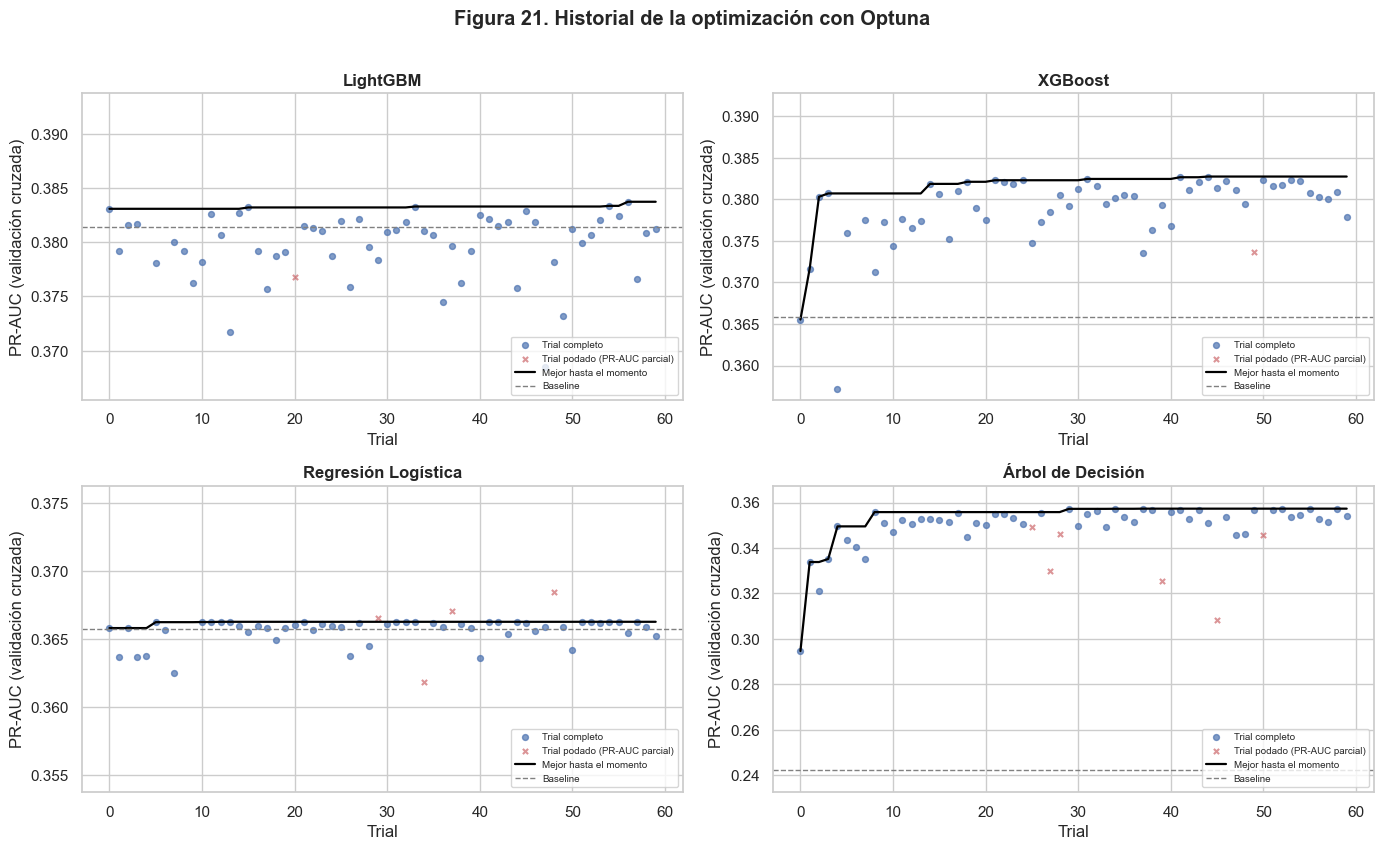

In [8]:
n = len(MODELOS_OPT)
columnas_fig = 2
filas_fig = int(np.ceil(n / columnas_fig))
fig, axes = plt.subplots(filas_fig, columnas_fig, figsize=(14, 4.2 * filas_fig), squeeze=False)
for ax, modelo in zip(axes.flat, MODELOS_OPT):
    h = estudios[modelo].trials_dataframe(attrs=("number", "value", "state"))
    completos = h[h["state"] == "COMPLETE"]
    podados = h[h["state"] == "PRUNED"]
    ax.scatter(completos["number"], completos["value"], s=18, color="#4C72B0", alpha=0.7, label="Trial completo")
    if len(podados):
        ax.scatter(podados["number"], podados["value"], s=14, marker="x", color="#C44E52", alpha=0.6,
                   label="Trial podado (PR-AUC parcial)")
    mejor = completos.set_index("number")["value"].reindex(h["number"]).ffill().cummax()
    ax.plot(h["number"], mejor, color="black", lw=1.6, label="Mejor hasta el momento")
    ax.axhline(baseline[modelo]["por_fold"]["pr_auc"].mean(), color="gray", ls="--", lw=1, label="Baseline")
    ax.set_title(MODELOS[modelo][1])
    ax.set_xlabel("Trial")
    ax.set_ylabel("PR-AUC (validación cruzada)")
    valores = completos["value"]
    if len(valores):
        piso_eje = min(valores.quantile(0.1), baseline[modelo]["por_fold"]["pr_auc"].mean())
        ax.set_ylim(piso_eje - 0.01, valores.max() + 0.01)
    ax.legend(fontsize=7, loc="lower right")
for ax in axes.flat[n:]:
    ax.axis("off")
fig.suptitle("Figura 21. Historial de la optimización con Optuna", fontweight="bold", y=1.01)
fig.tight_layout()
guardar_figura(fig, "opt_01_historial")
plt.show()

### 4.2. Importancia de los hiperparámetros

Optuna estima qué hiperparámetros explican la mayor parte de la variación del desempeño entre *trials* (método fANOVA). Ayuda a interpretar la búsqueda: los hiperparámetros con importancia baja podrían fijarse en futuras optimizaciones.

**Reproducibilidad de la estimación.** fANOVA se calcula ajustando un *random forest* sobre los *trials*, por lo que su resultado depende de una semilla aleatoria. Sin semilla fija, cada ejecución daba importancias distintas aunque los *trials* fueran idénticos. Por eso se calcula con **10 semillas fijas** y se informa la media y el desvío: el resultado es reproducible y el desvío muestra cuánta incertidumbre tiene la propia estimación.

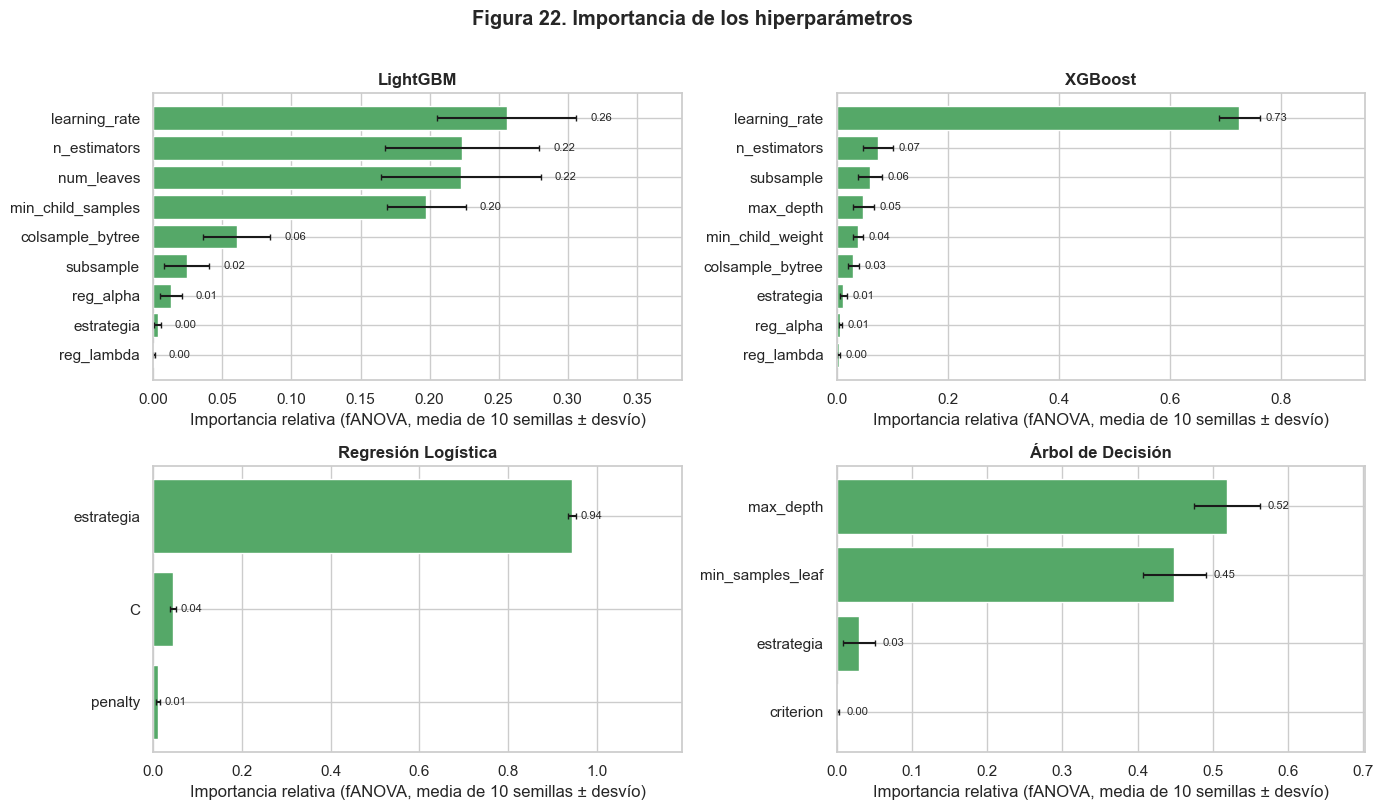

,LightGBM,XGBoost,Regresión Logística,Árbol de Decisión
Hiperparámetro,,,,
learning_rate,0.2560,0.7260,NaN,NaN
num_leaves,0.2230,NaN,NaN,NaN
min_child_samples,0.1970,NaN,NaN,NaN
n_estimators,0.2230,0.0750,NaN,NaN
colsample_bytree,0.0600,0.0300,NaN,NaN
subsample,0.0240,0.0600,NaN,NaN
reg_alpha,0.0130,0.0070,NaN,NaN
estrategia,0.0030,0.0120,0.9440,0.0300
reg_lambda,0.0010,0.0040,NaN,NaN


In [9]:
SEMILLAS_FANOVA = range(config.SEED, config.SEED + 10)
importancias, importancias_desvio = {}, {}
for modelo in MODELOS_OPT:
    try:
        estimaciones = pd.DataFrame([
            optuna.importance.get_param_importances(
                estudios[modelo], evaluator=optuna.importance.FanovaImportanceEvaluator(seed=semilla))
            for semilla in SEMILLAS_FANOVA
        ])
        importancias[modelo] = estimaciones.mean().to_dict()
        importancias_desvio[modelo] = estimaciones.std().to_dict()
    except Exception as error:  # requiere al menos 2 trials completos con variación
        print(f"{MODELOS[modelo][1]}: no se pudo calcular la importancia ({error})")

fig, axes = plt.subplots(filas_fig, columnas_fig, figsize=(14, 4 * filas_fig), squeeze=False)
for ax, modelo in zip(axes.flat, MODELOS_OPT):
    if modelo in importancias:
        imp = pd.Series(importancias[modelo]).sort_values()
        desvio = pd.Series(importancias_desvio[modelo]).reindex(imp.index)
        ax.barh(imp.index, imp.values, xerr=desvio.values, color="#55A868", capsize=2)
        for i, (v, d) in enumerate(zip(imp.values, desvio.fillna(0).values)):
            ax.text(v + d + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
        ax.set_xlim(0, max((imp + desvio.fillna(0)).max() * 1.25, 0.1))
    ax.set_title(MODELOS[modelo][1])
    ax.set_xlabel("Importancia relativa (fANOVA, media de 10 semillas ± desvío)")
for ax in axes.flat[n:]:
    ax.axis("off")
fig.suptitle("Figura 22. Importancia de los hiperparámetros", fontweight="bold", y=1.01)
fig.tight_layout()
guardar_figura(fig, "opt_02_importancia_hiperparametros")
plt.show()

tabla_importancias = pd.DataFrame(importancias).rename(columns=lambda m: MODELOS[m][1])
tabla_importancias.index.name = "Hiperparámetro"
guardar_tabla(tabla_importancias, "opt_importancia_hiperparametros", index=True)
tabla_importancias.round(3)

### 4.3. Mejores configuraciones encontradas

In [10]:
filas = []
for modelo in MODELOS_OPT:
    o = optimizado[modelo]
    filas.append({"Modelo": MODELOS[modelo][1], "Mejor trial": o["mejor_trial"],
                  "Estrategia": ESTRATEGIAS[o["estrategia"]],
                  "Hiperparámetros": ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}"
                                               for k, v in o["params"].items())})
mejores = pd.DataFrame(filas)
guardar_tabla(mejores, "opt_mejores_configuraciones")
pd.set_option("display.max_colwidth", 200)
mejores

,Modelo,Mejor trial,Estrategia,Hiperparámetros
0,LightGBM,56,Sin tratamiento,"n_estimators=108, learning_rate=0.05195, num_leaves=50, min_child_samples=22, subsample=0.9181, subsample_freq=1, colsample_bytree=0.9533, reg_alpha=0.02007, reg_lambda=3.945"
1,XGBoost,44,Sin tratamiento,"n_estimators=384, learning_rate=0.01111, max_depth=7, min_child_weight=12.94, subsample=0.7628, colsample_bytree=0.7331, reg_alpha=0.3723, reg_lambda=0.001506"
2,Regresión Logística,51,Sin tratamiento,"C=0.01296, penalty=l2, solver=liblinear"
3,Árbol de Decisión,37,Sin tratamiento,"max_depth=18, min_samples_leaf=364, criterion=gini"


## 5. Comparación: baseline frente a modelos optimizados

### 5.1. Mejora por modelo

Como el baseline y el modelo optimizado se evalúan con los mismos folds, la mejora se mide **fold a fold** (diferencia pareada). Además de la PR-AUC se comparan la ROC-AUC, el F1 con umbral óptimo, la calibración (Brier) y la brecha de sobreajuste.

In [11]:
def fila_resultados(nombre, version, estrategia, por_fold, oof):
    _, f1_opt = umbral_f1_optimo(y, oof)
    return {"Modelo": nombre, "Versión": version, "Estrategia": ESTRATEGIAS[estrategia],
            "PR-AUC": por_fold["pr_auc"].mean(), "PR-AUC (desvío)": por_fold["pr_auc"].std(),
            "ROC-AUC": por_fold["roc_auc"].mean(), "F1 con umbral óptimo": f1_opt,
            "Brier": por_fold["brier"].mean(), "PR-AUC entrenamiento": por_fold["pr_auc_train"].mean(),
            "Brecha de sobreajuste": por_fold["pr_auc_train"].mean() - por_fold["pr_auc"].mean(),
            "Segundos (5 folds)": por_fold["segundos_ajuste"].sum()}


filas, mejoras = [], []
for modelo in MODELOS_OPT:
    nombre = MODELOS[modelo][1]
    b, o = baseline[modelo], optimizado[modelo]
    filas.append(fila_resultados(nombre, "Baseline", b["estrategia"], b["por_fold"], b["oof"]))
    filas.append(fila_resultados(nombre, "Optimizado", o["estrategia"], o["por_fold"], o["oof"]))
    dif = o["por_fold"].set_index("fold")["pr_auc"] - b["por_fold"].set_index("fold")["pr_auc"]
    mejoras.append({"Modelo": nombre, "Δ PR-AUC (media)": dif.mean(), "Δ PR-AUC (desvío)": dif.std(),
                    "Folds con mejora": int((dif > 0).sum()), "Supera al baseline": "Sí" if dif.mean() > 0 else "No"})
comparacion = pd.DataFrame(filas)
mejoras = pd.DataFrame(mejoras)
guardar_tabla(comparacion, "opt_comparacion_baseline")
guardar_tabla(mejoras, "opt_mejora_pareada")
comparacion

,Modelo,Versión,Estrategia,PR-AUC,PR-AUC (desvío),ROC-AUC,F1 con umbral óptimo,Brier,PR-AUC entrenamiento,Brecha de sobreajuste,Segundos (5 folds)
0,LightGBM,Baseline,Sin tratamiento,0.3814,0.0143,0.7442,0.4566,0.1415,0.4898,0.1084,1.2055
1,LightGBM,Optimizado,Sin tratamiento,0.3837,0.0142,0.7451,0.4570,0.1413,0.4725,0.0888,2.1921
2,XGBoost,Baseline,Sin tratamiento,0.3659,0.0093,0.7352,0.4500,0.1441,0.5907,0.2248,1.2228
3,XGBoost,Optimizado,Sin tratamiento,0.3827,0.0154,0.7450,0.4578,0.1413,0.4535,0.0707,5.8323
4,Regresión Logística,Baseline,Sin tratamiento,0.3658,0.0153,0.7361,0.4509,0.1429,0.3676,0.0018,1.2507
5,Regresión Logística,Optimizado,Sin tratamiento,0.3663,0.0145,0.7357,0.4510,0.1429,0.3679,0.0016,1.2955
6,Árbol de Decisión,Baseline,Submuestreo aleatorio,0.2424,0.0059,0.5958,0.3719,0.4015,0.4625,0.2200,0.7744
7,Árbol de Decisión,Optimizado,Sin tratamiento,0.3573,0.0091,0.7315,0.4482,0.1435,0.3799,0.0226,0.6783


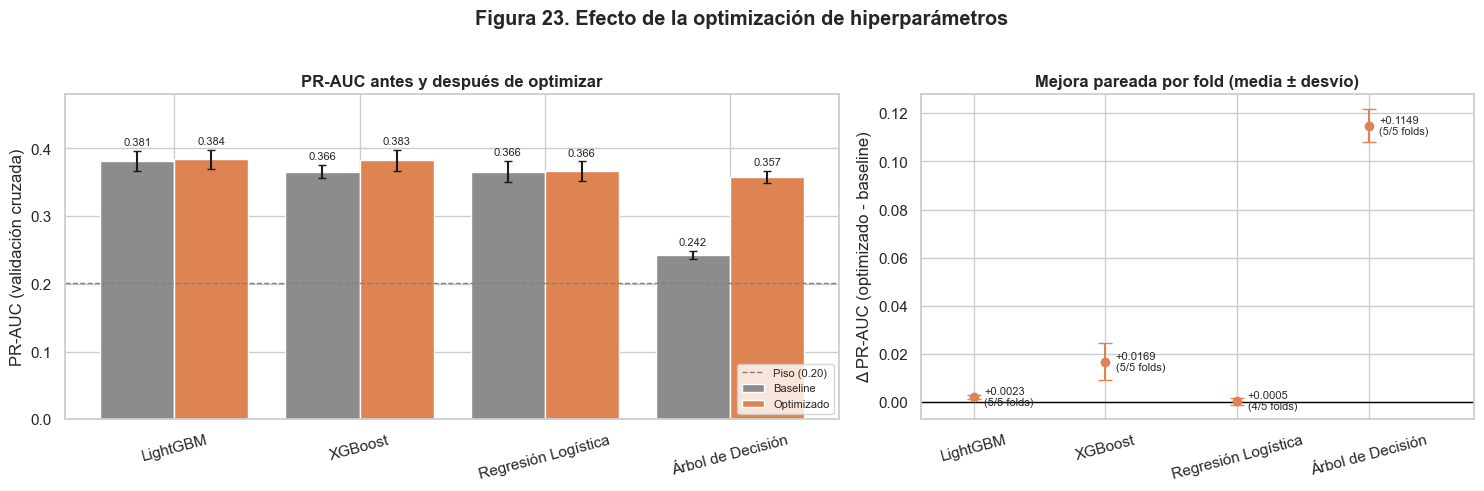

,Modelo,Δ PR-AUC (media),Δ PR-AUC (desvío),Folds con mejora,Supera al baseline
0,LightGBM,0.0023,0.0010,5,Sí
1,XGBoost,0.0169,0.0077,5,Sí
2,Regresión Logística,0.0005,0.0014,4,Sí
3,Árbol de Decisión,0.1149,0.0068,5,Sí


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
nombres = [MODELOS[m][1] for m in MODELOS_OPT]
x = np.arange(len(nombres))
for desplazamiento, version, color in [(-0.2, "Baseline", "#8C8C8C"), (0.2, "Optimizado", "#DD8452")]:
    sub = comparacion[comparacion["Versión"] == version].set_index("Modelo").loc[nombres]
    axes[0].bar(x + desplazamiento, sub["PR-AUC"], width=0.4, yerr=sub["PR-AUC (desvío)"], capsize=3,
                color=color, label=version)
    for xi, v, d in zip(x + desplazamiento, sub["PR-AUC"], sub["PR-AUC (desvío)"]):
        axes[0].text(xi, v + d + 0.008, f"{v:.3f}", ha="center", fontsize=8)
axes[0].axhline(y.mean(), color="gray", ls="--", lw=1, label=f"Piso ({y.mean():.2f})")
axes[0].set_xticks(x)
axes[0].set_xticklabels(nombres, rotation=15)
axes[0].set_ylim(0, comparacion["PR-AUC"].max() * 1.25)
axes[0].set_ylabel("PR-AUC (validación cruzada)")
axes[0].set_title("PR-AUC antes y después de optimizar")
axes[0].legend(fontsize=8, loc="lower right")

sub = mejoras.set_index("Modelo").loc[nombres]
axes[1].errorbar(x, sub["Δ PR-AUC (media)"], yerr=sub["Δ PR-AUC (desvío)"], fmt="o", capsize=5, color="#DD8452")
axes[1].axhline(0, color="black", lw=1)
for xi, (v, k) in enumerate(zip(sub["Δ PR-AUC (media)"], sub["Folds con mejora"])):
    axes[1].text(xi + 0.08, v, f"{v:+.4f}\n({k}/5 folds)", va="center", fontsize=8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(nombres, rotation=15)
axes[1].set_xlim(-0.4, len(nombres) - 0.2)
axes[1].set_ylabel("Δ PR-AUC (optimizado - baseline)")
axes[1].set_title("Mejora pareada por fold (media ± desvío)")
fig.suptitle("Figura 23. Efecto de la optimización de hiperparámetros", fontweight="bold", y=1.02)
fig.tight_layout()
guardar_figura(fig, "opt_03_baseline_vs_optimizado")
plt.show()
mejoras

## 6. Selección del modelo final

### 6.1. Criterio

Para cada modelo se toma su **mejor versión**: la optimizada, salvo que no supere a su baseline (en ese caso se conserva la configuración del baseline). Entre esas versiones se selecciona la de **mayor PR-AUC media** en validación cruzada. Para evaluar si la ventaja sobre el segundo es consistente, se compara fold a fold: si el mejor supera al segundo en la mayoría de los folds, la elección es robusta; si no, la diferencia está dentro de la variabilidad y se informa como tal.

El Árbol de Decisión optimizado no compite por la selección: se conserva como **modelo interpretable de referencia** para extraer reglas en el notebook 05.

In [13]:
# Mejor versión de cada modelo: la optimizada, salvo que no supere al baseline
elegido = {}
for modelo in MODELOS_OPT:
    b, o = baseline[modelo], optimizado[modelo]
    if o["por_fold"]["pr_auc"].mean() >= b["por_fold"]["pr_auc"].mean():
        elegido[modelo] = {**o, "version": "optimizado"}
    else:
        elegido[modelo] = {"estrategia": b["estrategia"], "params": {}, "por_fold": b["por_fold"], "oof": b["oof"],
                           "version": "baseline"}
        print(f"{MODELOS[modelo][1]}: el baseline supera a la versión optimizada; se conserva el baseline.")

competidores = [m for m in MODELOS_OPT if candidatos.set_index("modelo").loc[m, "Rol"] == "Candidato a optimizar"]
ranking_opt = sorted(competidores, key=lambda m: elegido[m]["por_fold"]["pr_auc"].mean(), reverse=True)
final, segundo = ranking_opt[0], ranking_opt[1]

pf_final = elegido[final]["por_fold"].set_index("fold")["pr_auc"]
pf_segundo = elegido[segundo]["por_fold"].set_index("fold")["pr_auc"]
dif = pf_final - pf_segundo
folds_ganados = int((dif > 0).sum())

print(f"Modelo final: {MODELOS[final][1]}, versión {elegido[final]['version']} (PR-AUC {pf_final.mean():.4f} ± {pf_final.std():.4f})")
print(f"Segundo:      {MODELOS[segundo][1]}, versión {elegido[segundo]['version']} (PR-AUC {pf_segundo.mean():.4f} ± {pf_segundo.std():.4f})")
print(f"Diferencia media: {dif.mean():+.4f} | el modelo final gana en {folds_ganados} de {len(dif)} folds")
print("Elección robusta." if folds_ganados >= 4 else "La diferencia está dentro de la variabilidad entre folds.")

resumen["Modelo final"] = f"{MODELOS[final][1]} (versión {elegido[final]['version']})"
resumen["PR-AUC del modelo final (validación cruzada)"] = f"{pf_final.mean():.4f} ± {pf_final.std():.4f}"
resumen["ROC-AUC del modelo final"] = f"{elegido[final]['por_fold']['roc_auc'].mean():.4f}"
resumen["Ventaja sobre el segundo"] = f"{dif.mean():+.4f} ({MODELOS[segundo][1]}; gana en {folds_ganados}/5 folds)"

Modelo final: LightGBM, versión optimizado (PR-AUC 0.3837 ± 0.0142)
Segundo:      XGBoost, versión optimizado (PR-AUC 0.3827 ± 0.0154)
Diferencia media: +0.0010 | el modelo final gana en 3 de 5 folds
La diferencia está dentro de la variabilidad entre folds.


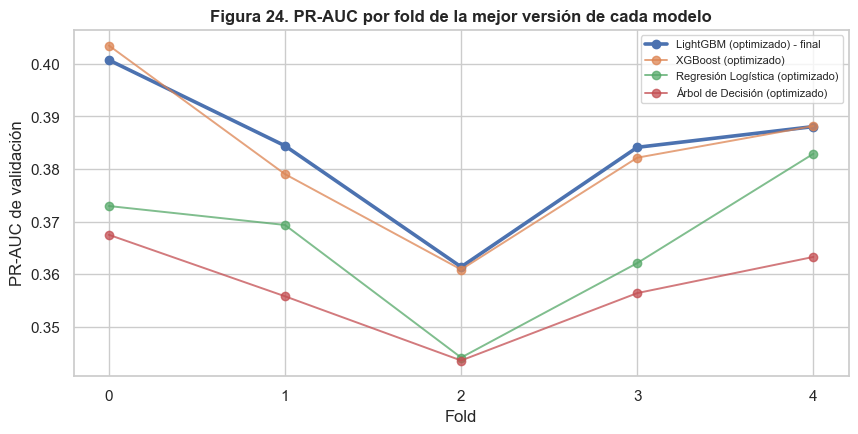

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for modelo in MODELOS_OPT:
    pf = elegido[modelo]["por_fold"]
    estilo = dict(lw=2.6, marker="o") if modelo == final else dict(lw=1.4, marker="o", alpha=0.75)
    ax.plot(pf["fold"], pf["pr_auc"], label=f"{MODELOS[modelo][1]} ({elegido[modelo]['version']})"
            + (" - final" if modelo == final else ""), **estilo)
ax.set_xticks(sorted(np.unique(folds)))
ax.set_xlabel("Fold")
ax.set_ylabel("PR-AUC de validación")
ax.set_title("Figura 24. PR-AUC por fold de la mejor versión de cada modelo")
ax.legend(fontsize=8)
guardar_figura(fig, "opt_04_optimizados_folds")
plt.show()

### 6.2. Configuración seleccionada

Se guarda la configuración del modelo final y la del árbol de referencia en `opt_seleccion.json`. El notebook 05 la usará para entrenar ambos modelos con todo el conjunto de entrenamiento, ajustar el umbral de decisión y evaluarlos **una única vez** en el conjunto de prueba.

In [15]:
def a_json(valor):
    return valor.item() if hasattr(valor, "item") else valor


seleccion = {
    "datos": resumen["Datos utilizados"],
    "dataset_sha256": etiquetas["dataset_sha256"],
    "modelo_final": {"modelo": final, "version": elegido[final]["version"], "estrategia": elegido[final]["estrategia"],
                     "params": {k: a_json(v) for k, v in elegido[final]["params"].items()},
                     "pr_auc_cv": float(pf_final.mean()), "pr_auc_cv_desvio": float(pf_final.std())},
}
if "arbol" in elegido:
    pf_arbol = elegido["arbol"]["por_fold"]["pr_auc"]
    seleccion["referencia_interpretable"] = {
        "modelo": "arbol", "version": elegido["arbol"]["version"], "estrategia": elegido["arbol"]["estrategia"],
        "params": {k: a_json(v) for k, v in elegido["arbol"]["params"].items()},
        "pr_auc_cv": float(pf_arbol.mean()), "pr_auc_cv_desvio": float(pf_arbol.std())}

ruta_seleccion = config.TABLES_DIR / ("opt_seleccion_muestra.json" if USAR_MUESTRA else "opt_seleccion.json")
ruta_seleccion.write_text(json.dumps(seleccion, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Selección guardada en: {ruta_seleccion}")
print(json.dumps(seleccion, indent=2, ensure_ascii=False))

Selección guardada en: C:\Users\poriglia\tfi-mineria-datos-noshow\reports\tables\opt_seleccion.json
{
  "datos": "Dataset completo",
  "dataset_sha256": "40d361e54c4cd001e1c062e326c199206e44089db0d0ceb24d7879bd8a0413e6",
  "modelo_final": {
    "modelo": "lightgbm",
    "version": "optimizado",
    "estrategia": "ninguna",
    "params": {
      "n_estimators": 108,
      "learning_rate": 0.05194964150567601,
      "num_leaves": 50,
      "min_child_samples": 22,
      "subsample": 0.9181331372497834,
      "subsample_freq": 1,
      "colsample_bytree": 0.9533138056920186,
      "reg_alpha": 0.020074100888057035,
      "reg_lambda": 3.944568768649456
    },
    "pr_auc_cv": 0.3837445361104329,
    "pr_auc_cv_desvio": 0.01422092426004445
  },
  "referencia_interpretable": {
    "modelo": "arbol",
    "version": "optimizado",
    "estrategia": "ninguna",
    "params": {
      "max_depth": 18,
      "min_samples_leaf": 364,
      "criterion": "gini"
    },
    "pr_auc_cv": 0.35729230778112

## 7. Trazabilidad en MLflow

Se verifica que el experimento `03_optuna` contenga una corrida padre por modelo y una corrida hija por cada *trial*, todas con el mismo *hash* de dataset.

Para explorarlo en la interfaz: `mlflow ui --backend-store-uri sqlite:///mlflow.db`. En la tabla de corridas, las corridas hijas aparecen agrupadas bajo cada estudio (se despliegan con el ícono **+**).

In [16]:
corridas = exportar_corridas(["optuna"], USAR_MUESTRA)
estudios_mlflow = corridas[corridas["tags.tipo"] == "estudio"]
trials_mlflow = corridas[corridas["tags.tipo"] == "trial"]

assert len(estudios_mlflow) == len(MODELOS_OPT), "Falta alguna corrida padre"
assert len(trials_mlflow) == N_TRIALS * len(MODELOS_OPT), "La cantidad de trials registrados no coincide"
assert corridas["tags.dataset_sha256"].nunique() == 1, "Hay corridas con datasets distintos"
assert trials_mlflow["tags.mlflow.parentRunId"].isin(estudios_mlflow["run_id"]).all(), "Hay trials sin corrida padre"

conteo = trials_mlflow.groupby(["tags.modelo", "tags.estado"]).size().unstack(fill_value=0)
conteo.index = conteo.index.map(lambda m: MODELOS[m][1])
guardar_tabla(conteo, "opt_trials_por_estado", index=True)
resumen["Corridas registradas en MLflow (03_optuna)"] = f"{len(estudios_mlflow)} estudios + {len(trials_mlflow)} trials"
print(f"Estudios: {len(estudios_mlflow)} | Trials: {len(trials_mlflow)} | Dataset: {corridas['tags.dataset_sha256'].iloc[0][:12]}...")
conteo

Estudios: 4 | Trials: 240 | Dataset: 40d361e54c4c...


tags.estado,completo,podado
tags.modelo,,
Árbol de Decisión,54,6
LightGBM,59,1
Regresión Logística,56,4
XGBoost,59,1


### 7.1. Exportación del resumen

In [17]:
cifras = pd.DataFrame(list(resumen.items()), columns=["Indicador", "Valor"])
lineas = [
    "# Resumen de la optimización con Optuna",
    "",
    f"**Datos utilizados:** {resumen['Datos utilizados']}",
    "",
    "## Cifras clave",
    "",
    tabla_markdown(cifras),
    "",
    "## Espacios de búsqueda",
    "",
    tabla_markdown(espacios),
    "",
    "## Mejores configuraciones",
    "",
    tabla_markdown(mejores),
    "",
    "## Importancia de los hiperparámetros (fANOVA)",
    "",
    tabla_markdown(tabla_importancias.round(3).fillna("-"), index=True),
    "",
    "## Baseline frente a optimizado",
    "",
    tabla_markdown(comparacion.round(4)),
    "",
    "## Mejora pareada por fold",
    "",
    tabla_markdown(mejoras.round(4)),
    "",
    "## Trials por estado",
    "",
    tabla_markdown(conteo, index=True),
    "",
]
ruta_resumen = config.TABLES_DIR / "opt_resumen.md"
ruta_resumen.write_text("\n".join(lineas), encoding="utf-8")
print(f"Resumen guardado en: {ruta_resumen}")
cifras

Resumen guardado en: C:\Users\poriglia\tfi-mineria-datos-noshow\reports\tables\opt_resumen.md


,Indicador,Valor
0,Datos utilizados,Dataset completo
1,Trials por modelo,60
2,Modelo final,LightGBM (versión optimizado)
3,PR-AUC del modelo final (validación cruzada),0.3837 ± 0.0142
4,ROC-AUC del modelo final,0.7451
5,Ventaja sobre el segundo,+0.0010 (XGBoost; gana en 3/5 folds)
6,Corridas registradas en MLflow (03_optuna),4 estudios + 240 trials
